# Tugas Praktikum Modul 5 No. 3 — Sistem Kendali Fuzzy Pemberian Tip

**Antesenden (Input):**
- Kualitas pelayanan (0–10): buruk, baik, sangat baik
- Kualitas makanan (0–10): buruk, layak, sangat enak

**Konsekuensi (Output):**
- Pemberian tip (0–25%): rendah, sedang, tinggi

**Aturan:**
1. JIKA pelayanan bagus (sangat baik) ATAU makanan bagus (sangat enak), MAKA tip tinggi.
2. JIKA pelayanan rata-rata (baik), MAKA tip sedang.
3. JIKA pelayanan buruk DAN makanan buruk, MAKA tip rendah.

In [3]:
%pip install scikit-fuzzy networkx


  Using cached scikit_fuzzy-0.5.0-py2.py3-none-any.whl.metadata (2.6 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
Using cached scikit_fuzzy-0.5.0-py2.py3-none-any.whl (920 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)

   ---------------------------------------- 0/2 [scikit-fuzzy]
   ---------------------------------------- 0/2 [scikit-fuzzy]
   ---------------------------------------- 0/2 [scikit-fuzzy]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- ------------------- 1/2 [networkx]
   -------------------- -----

In [ ]:
import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

## a. Program Sistem Kendali Fuzzy

In [5]:
# Antesenden (input) & konsekuensi (output)
pelayanan = ctrl.Antecedent(np.arange(0, 11, 1), 'pelayanan')
makanan = ctrl.Antecedent(np.arange(0, 11, 1), 'makanan')
tip = ctrl.Consequent(np.arange(0, 26, 1), 'tip')

# Himpunan fuzzy input
pelayanan['buruk'] = fuzz.trimf(pelayanan.universe, [0, 0, 5])
pelayanan['baik'] = fuzz.trimf(pelayanan.universe, [0, 5, 10])
pelayanan['sangat baik'] = fuzz.trimf(pelayanan.universe, [5, 10, 10])

makanan['buruk'] = fuzz.trimf(makanan.universe, [0, 0, 5])
makanan['layak'] = fuzz.trimf(makanan.universe, [0, 5, 10])
makanan['sangat enak'] = fuzz.trimf(makanan.universe, [5, 10, 10])

# Himpunan fuzzy output
tip['rendah'] = fuzz.trimf(tip.universe, [0, 0, 13])
tip['sedang'] = fuzz.trimf(tip.universe, [0, 13, 25])
tip['tinggi'] = fuzz.trimf(tip.universe, [13, 25, 25])

c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


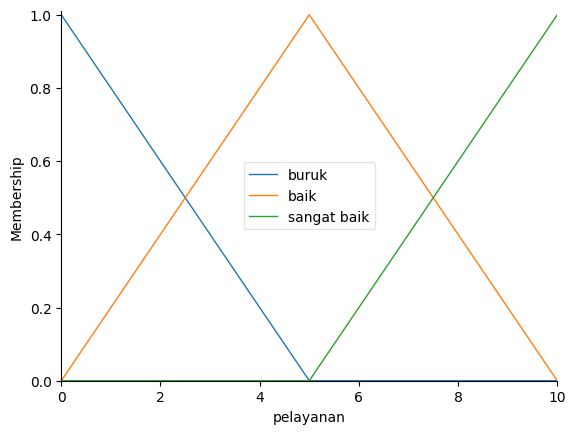

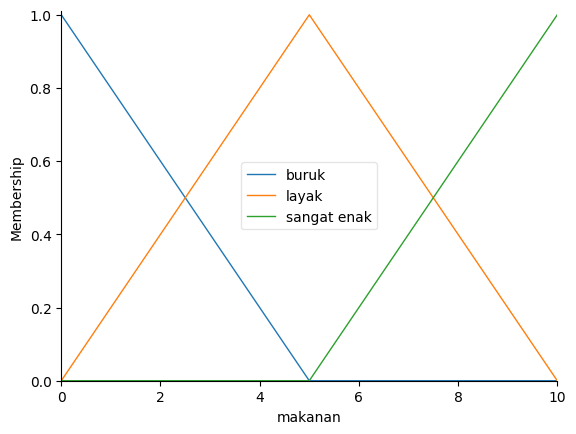

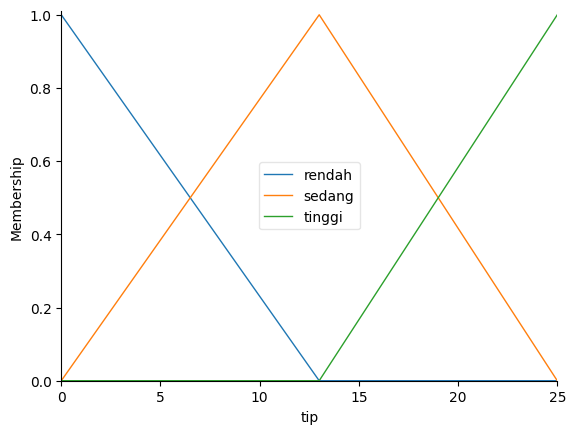

In [6]:
# Visualisasi fungsi keanggotaan
pelayanan.view()
makanan.view()
tip.view()

In [7]:
# Aturan
rule1 = ctrl.Rule(pelayanan['sangat baik'] | makanan['sangat enak'], tip['tinggi'])
rule2 = ctrl.Rule(pelayanan['baik'], tip['sedang'])
rule3 = ctrl.Rule(pelayanan['buruk'] & makanan['buruk'], tip['rendah'])

# Sistem kendali
tipping_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
tipping = ctrl.ControlSystemSimulation(tipping_ctrl)

## b. Prediksi Tip

In [8]:
data = [(9.8, 6.8), (9.5, 9.2), (6.4, 9.6), (5.7, 6.3), (1.3, 2.5), (7.4, 6.8)]

hasil = []
for p, m in data:
    tipping.input['pelayanan'] = p
    tipping.input['makanan'] = m
    tipping.compute()
    hasil.append([p, m, round(tipping.output['tip'], 2)])

df = pd.DataFrame(hasil, columns=['Kualitas layanan', 'Kualitas makanan', 'Tip yang diberikan (%)'])
df

,Kualitas layanan,Kualitas makanan,Tip yang diberikan (%)
0,9.8,6.8,19.85
1,9.5,9.2,18.48
2,6.4,9.6,14.76
3,5.7,6.3,13.03
4,1.3,2.5,9.89
5,7.4,6.8,13.93


c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


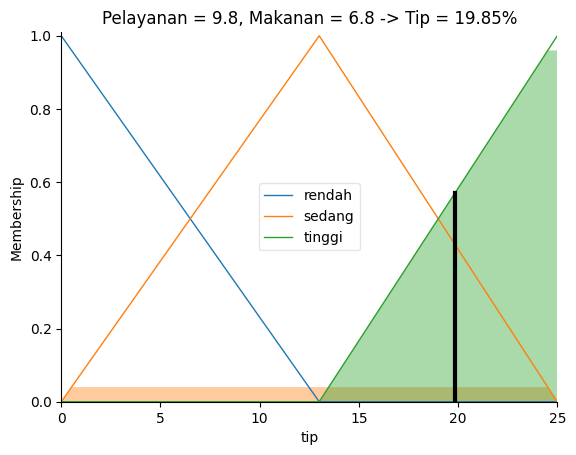

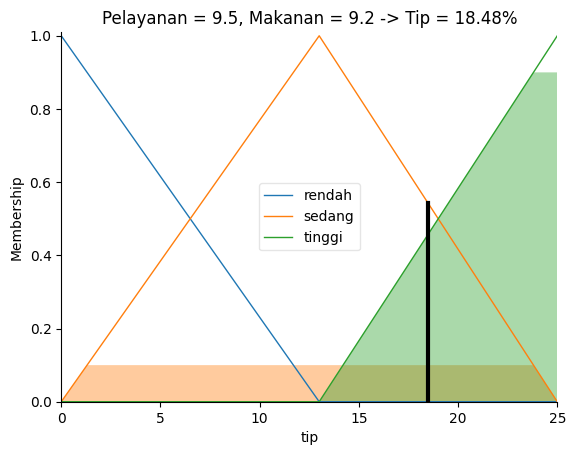

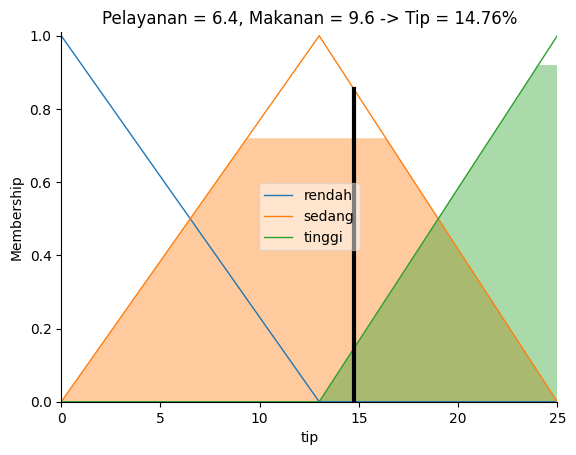

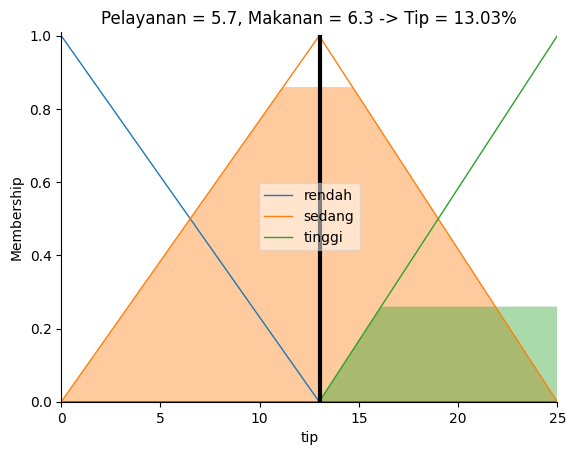

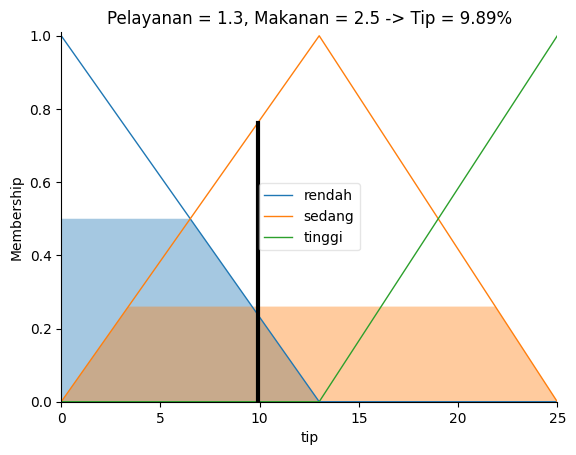

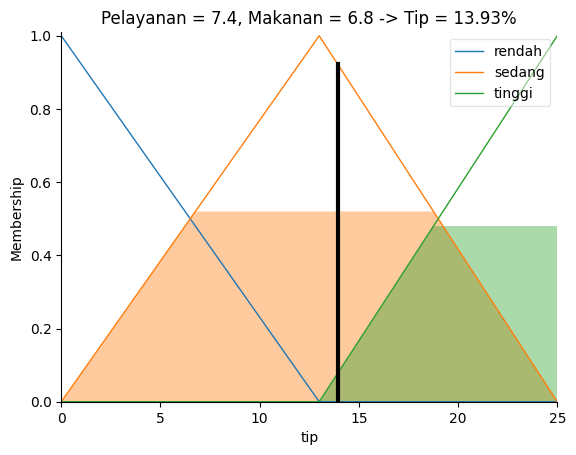

In [9]:
# Visualisasi hasil defuzzifikasi untuk setiap data
for p, m in data:
    tipping.input['pelayanan'] = p
    tipping.input['makanan'] = m
    tipping.compute()
    tip.view(sim=tipping)
    plt.title(f"Pelayanan = {p}, Makanan = {m} -> Tip = {tipping.output['tip']:.2f}%")
    plt.show()